# EDA conjunto — Data4Cyber sin S0 ni S3- 

Análisis exploratorio sobre las ** tablas de proceso** del release, unidas en un solo
`DataFrame` con la columna `escenario`.

**Cómo se ejecuta.** La celda 0 resuelve sola la ruta de datos: monta Drive si corre en
Colab y cae a `datasets/` si corre local. No hay rutas absolutas en ninguna otra celda.
***Se utiliza hasta el escenario S5 ya que hay datos sin comprender en el escenario S6***

In [1]:
# === 0. Configuración y carga de los escenarios ===

%matplotlib inline
import os


from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys

# --- helpers del EDA: src2/ vive al lado del notebook ---
sys.path.insert(0, str(Path.cwd()))
from src2.data import (mostrar_dfs, eliminar_columnas, imputar_media,
                       partir, tipo_de, fase_de)
import src2.split as split
#from src2.train import *
import src2.train as train  
from src2.group import GroupedPCA

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
#from src2.reduce import BlockPca

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score,
                             roc_auc_score)



#rom google.colab import drive
#rive.mount("/content/gdrive/")
BASE =Path("/media/windows/Users/pablo/Documents/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab/datasets/")


import pandas as pd

dfs = {
    "S0":     pd.read_csv(BASE / "datasetS0.csv"),
    "S1":     pd.read_csv(BASE / "datasetS1.csv"),
    "S1-alt": pd.read_csv(BASE / "datasetS1alt.csv"),
    "S2":     pd.read_csv(BASE / "datasetS2.csv"),
    "S3":     pd.read_csv(BASE / "datasetS3.csv"),
    "S4":     pd.read_csv(BASE / "datasetS4.csv"),
    "S5":     pd.read_csv(BASE / "datasetS5.csv"),
    "S6":     pd.read_csv(BASE / "datasetS6.csv"),
}
df = (pd.concat(dfs, names=["escenario"])
      .reset_index(level="escenario")
      .reset_index(drop=True))

/tmp/ipykernel_2368738/1112434868.py:57: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index(level="escenario")


In [2]:
print(df)

      escenario                         timestamp  attack_active attack_phase attack_phase_all  BSS-Inverter-AC-Meter.cos_phi1  BSS-Inverter-AC-Meter.cos_phi2  \
0            S0  2026-03-05 13:19:02.660000+00:00          False       normal           normal                       -0.310502                       -0.703539   
1            S0  2026-03-05 13:19:03.660000+00:00          False       normal           normal                       -0.310502                       -0.703539   
2            S0  2026-03-05 13:19:04.660000+00:00          False       normal           normal                       -0.310502                       -0.703539   
3            S0  2026-03-05 13:19:05.660000+00:00          False       normal           normal                       -0.310502                       -0.703539   
4            S0  2026-03-05 13:19:06.660000+00:00          False       normal           normal                       -0.999527                       -0.959250   
...         ...             

In [3]:
# --- agrupación de columnas: dispositivo, tipo, fase ---
SIG_TIPO = {
    "uln1": "Tensión fase-neutro", "uln2": "Tensión fase-neutro", "uln3": "Tensión fase-neutro",
    "ull12": "Tensión fase-fase", "ull23": "Tensión fase-fase", "ull31": "Tensión fase-fase",
    "iln1": "Corriente de fase", "iln2": "Corriente de fase", "iln3": "Corriente de fase",
    "i_sum3": "Corriente de neutro",
    "pln1": "Potencia activa", "pln2": "Potencia activa", "pln3": "Potencia activa", "p_sum3": "Potencia activa",
    "sln1": "Potencia aparente", "sln2": "Potencia aparente", "sln3": "Potencia aparente", "s_sum3": "Potencia aparente",
    "qln1": "Potencia reactiva", "qln2": "Potencia reactiva", "qln3": "Potencia reactiva", "q_sum3": "Potencia reactiva",
    "cos_phi1": "Factor de potencia", "cos_phi2": "Factor de potencia", "cos_phi3": "Factor de potencia",
    "freq": "Frecuencia",
    "phase_seq": "Secuencia de fases",
    "realtime": "Marca de tiempo del equipo",
}
UNIDAD = {
    "Tensión fase-neutro": "V", "Tensión fase-fase": "V", "Corriente de fase": "A",
    "Corriente de neutro": "A", "Potencia activa": "W", "Potencia aparente": "VA",
    "Potencia reactiva": "var", "Factor de potencia": "—", "Frecuencia": "Hz",
    "Secuencia de fases": "—", "Marca de tiempo del equipo": "s",
    "SOC": "fracción 0-1", "Señal de precio": "EUR/kWh", "Contexto de escenario": "—",
    "Control / etiquetas": "—", "Desconocido": "?",
}
FASE = {"ull12": "L1-L2", "ull23": "L2-L3", "ull31": "L3-L1"}

reg = []
for c in df.columns:
    dev, sig = partir(c)
    t = tipo_de(dev, sig)
    reg.append({"columna": c, "dispositivo": dev, "señal": sig,
                "tipo": t, "unidad": UNIDAD.get(t, "?"), "fase": fase_de(sig)})
cols = pd.DataFrame(reg)

print("columnas:", len(cols), "| dispositivos:", cols.dispositivo.nunique(), "| tipos:", cols.tipo.nunique())
print("\n--- por dispositivo ---")
por_dev = (cols.groupby("dispositivo")
           .agg(columnas=("columna", "size"), tipos=("tipo", lambda s: ", ".join(sorted(set(s)))))
           .sort_values("columnas", ascending=False))
display(por_dev)

columnas: 157 | dispositivos: 10 | tipos: 15

--- por dispositivo ---


,columnas,tipos
dispositivo,,
BSS-Inverter-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Load-B-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Substation-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Load-A-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
PV-Inverter-AC-Meter,28,"Corriente de fase, Corriente de neutro, Factor..."
Profile,8,Contexto de escenario
(sin prefijo),5,Control / etiquetas
MQTT-Price-Signal,2,Señal de precio
Battery-SOC-Reference,1,SOC


In [4]:
# # === 1. Integridad del registro y de las etiquetas ===

# # --- una fila por escenario: paso temporal, cobertura, monotonía y concordancia etiqueta/fase ---
# filas = []
# for k, datos in dfs.items():
#     t = pd.to_datetime(datos["timestamp"], errors="coerce")
#     paso = t.diff().dt.total_seconds().dropna()
#     es_normal = datos["attack_phase"].eq("normal")
#     activo = datos["attack_active"].astype(bool)
#     filas.append({
#         "escenario": k,
#         "filas": len(datos),
#         "inicio": t.min(),
#         "duracion_min": round((t.max() - t.min()).total_seconds() / 60, 1),
#         "paso_s": paso.mode().iloc[0],
#         "pasos_distintos": paso.nunique(),
#         "timestamp_nulo": int(t.isna().sum()),
#         "monotonico": t.is_monotonic_increasing,
#         "positivos": int(activo.sum()),
#         "concuerda_con_fase": bool((activo == ~es_normal).all()),
#     })

# auditoria = pd.DataFrame(filas).set_index("escenario")
# print("auditoría del registro crudo, una fila por escenario")
# display(auditoria)


## 2. Datos Nulos

En este release **una celda vacía no es un cero ni un `NaN` imputado: es ausencia de valor de origen**.

In [5]:
# --- vacíos por columna y por fila ---

num = df.select_dtypes(include=[np.number])
no_num = [c for c in df.columns if c not in num.columns]
miss = df.isna()

print(f"columnas numéricas: {len(num.columns)} | no numéricas: {len(no_num)}")
if no_num:
    print("no numéricas:", no_num)

print(f"celdas vacías: {int(miss.values.sum()):,} de {miss.size:,} ({miss.values.mean()*100:.2f} %)")
print(f"filas con algún vacío: {int((miss.sum(axis=1) > 0).sum()):,} de {len(miss):,}")

por_col = miss.mean().mul(100).sort_values(ascending=False)
con_vacios = por_col[por_col > 0]
print(f"ncolumnas con al menos un vacío: {len(con_vacios)} de {len(por_col)}")
print("\ntop 15 columnas más incompletas (%):")
print(con_vacios.head(15).round(2).to_string())
#print(con_vacios.index.tolist())



columnas numéricas: 150 | no numéricas: 7
no numéricas: ['escenario', 'timestamp', 'attack_active', 'attack_phase', 'attack_phase_all', 'Profile.timestamp', 'MQTT-Price-Signal.event']
celdas vacías: 20,123 de 2,253,578 (0.89 %)
filas con algún vacío: 12,992 de 14,354
ncolumnas con al menos un vacío: 152 de 157

top 15 columnas más incompletas (%):
MQTT-Price-Signal.event                90.51
MQTT-Price-Signal.price_eur_per_kwh     6.77
Battery-SOC-Reported.soc_value          1.40
Profile.total_irradiance                1.37
Profile.pv_active_kw                    1.37
Profile.load1_kw                        1.37
Profile.pv_input_kw                     1.37
Profile.load2_kw                        1.37
Profile.ambient_temperature             1.37
Profile.pv_reactive_kvar                1.37
Profile.timestamp                       1.37
Battery-SOC-Reference.soc_value         0.35
BSS-Inverter-AC-Meter.i_sum3            0.22
BSS-Inverter-AC-Meter.qln3              0.22
BSS-Inverter-AC-Mete

 # Eliminar columnas sin aporte
 por ahora vamos a descartar las columas que involucren marcas temporales y etapas del ataque ya que no estamos interezados en analizar estas caracteristicas.
"

In [6]:
df=eliminar_columnas(df)

# Imputacion de datos 

In [7]:
df.loc[:, df.isna().any()]


,BSS-Inverter-AC-Meter.cos_phi1,BSS-Inverter-AC-Meter.cos_phi2,BSS-Inverter-AC-Meter.cos_phi3,BSS-Inverter-AC-Meter.freq,BSS-Inverter-AC-Meter.i_sum3,BSS-Inverter-AC-Meter.iln1,BSS-Inverter-AC-Meter.iln2,BSS-Inverter-AC-Meter.iln3,BSS-Inverter-AC-Meter.p_sum3,BSS-Inverter-AC-Meter.pln1,BSS-Inverter-AC-Meter.pln2,BSS-Inverter-AC-Meter.pln3,BSS-Inverter-AC-Meter.q_sum3,BSS-Inverter-AC-Meter.qln1,BSS-Inverter-AC-Meter.qln2,BSS-Inverter-AC-Meter.qln3,BSS-Inverter-AC-Meter.s_sum3,BSS-Inverter-AC-Meter.sln1,BSS-Inverter-AC-Meter.sln2,BSS-Inverter-AC-Meter.sln3,BSS-Inverter-AC-Meter.ull12,BSS-Inverter-AC-Meter.ull23,BSS-Inverter-AC-Meter.ull31,BSS-Inverter-AC-Meter.uln1,BSS-Inverter-AC-Meter.uln2,BSS-Inverter-AC-Meter.uln3,Battery-SOC-Reference.soc_value,Battery-SOC-Reported.soc_value,Load-A-AC-Meter.cos_phi1,Load-A-AC-Meter.cos_phi2,...,PV-Inverter-AC-Meter.ull31,PV-Inverter-AC-Meter.uln1,PV-Inverter-AC-Meter.uln2,PV-Inverter-AC-Meter.uln3,Substation-AC-Meter.cos_phi1,Substation-AC-Meter.cos_phi2,Substation-AC-Meter.cos_phi3,Substation-AC-Meter.freq,Substation-AC-Meter.i_sum3,Substation-AC-Meter.iln1,Substation-AC-Meter.iln2,Substation-AC-Meter.iln3,Substation-AC-Meter.p_sum3,Substation-AC-Meter.pln1,Substation-AC-Meter.pln2,Substation-AC-Meter.pln3,Substation-AC-Meter.q_sum3,Substation-AC-Meter.qln1,Substation-AC-Meter.qln2,Substation-AC-Meter.qln3,Substation-AC-Meter.s_sum3,Substation-AC-Meter.sln1,Substation-AC-Meter.sln2,Substation-AC-Meter.sln3,Substation-AC-Meter.ull12,Substation-AC-Meter.ull23,Substation-AC-Meter.ull31,Substation-AC-Meter.uln1,Substation-AC-Meter.uln2,Substation-AC-Meter.uln3
0,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.394920,0.377298,0.421309,-53.832207,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,235.498993,236.037918,NaN,NaN,-0.778859,0.997305,...,410.934448,237.135132,236.710876,237.264816,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,6802.083984,2306.897217,2242.235840,2252.951416,405.437134,405.948944,406.069855,234.270035,233.998840,234.615189
1,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.394920,0.377298,0.421309,-53.832207,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,235.498993,236.037918,0.199597,NaN,-0.778859,0.997305,...,410.934448,237.135132,236.710876,237.264816,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,6802.083984,2306.897217,2242.235840,2252.951416,405.437134,405.948944,406.069855,234.270035,233.998840,234.615189
2,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.394920,0.377298,0.421309,-53.832207,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,235.498993,236.037918,0.199597,NaN,-0.778859,0.997305,...,410.934448,237.135132,236.710876,237.264816,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,-1999.145142,-1944.466309,-1958.528809,1616.824585,541.077271,517.283081,558.464233,6802.083984,2306.897217,2242.235840,2252.951416,405.437134,405.948944,406.069855,234.270035,233.998840,234.615189
3,-0.310502,-0.703539,-0.989501,50.008049,0.101279,0.394920,0.377298,0.421309,-53.832207,-18.320284,-16.559868,-18.952057,28.835691,-2.792666,-9.061968,3.146089,281.451599,93.153397,88.853355,99.444839,407.938171,408.500793,408.841309,235.879349,235.498993,236.037918,0.199597,NaN,-0.778859,0.997305,...,410.934448,237.135132,236.710876,237.264816,-0.965705,-0.966816,-0.962146,50.005825,1.437780,9.847172,9.582252,9.602752,-5902.140137,-1999.145142,-1944.466309,-1958.528809,161

In [ ]:
# --- imputar la media por escenario y mostrar el resultado, no el estado previo ---
df =imputar_media(df)
print("nulos restantes:",df.isna().sum())

nulos restantes: escenario                         0
attack_active                     0
BSS-Inverter-AC-Meter.cos_phi1    0
BSS-Inverter-AC-Meter.cos_phi2    0
BSS-Inverter-AC-Meter.cos_phi3    0
                                 ..
Substation-AC-Meter.ull23         0
Substation-AC-Meter.ull31         0
Substation-AC-Meter.uln1          0
Substation-AC-Meter.uln2          0
Substation-AC-Meter.uln3          0
Length: 134, dtype: int64


# Split de Datos
Debido a la naturaleza temporal e interdependiente de las variables de telemetría ciberfísica, aplicar una división aleatoria convencional (*random train-test split*) introduce el riesgo de data leakage y overfitting, ya que el modelo tiende a memorizar tendencias continuas o correlaciones contiguas dentro de un mismo episodio operacional. Para capturar la dinámica secuencial de los sensores sin contaminar el entrenamiento, los datos se estructuraron mediante rolling windows de 20 pasos temporales hacia atrás. Asimismo, la validación del modelo se diseñó bajo un esquema de Leave-One-Scenario-Out(LOSO), lo que garantiza que el conjunto de prueba contenga únicamente eventos de ataque u operación completamente inéditos, evaluando con rigor la capacidad real de generalización del sistema ante situaciones no vistas

In [9]:
dfX = df.drop(["attack_active"],axis=1)
dfY=  df["attack_active"]

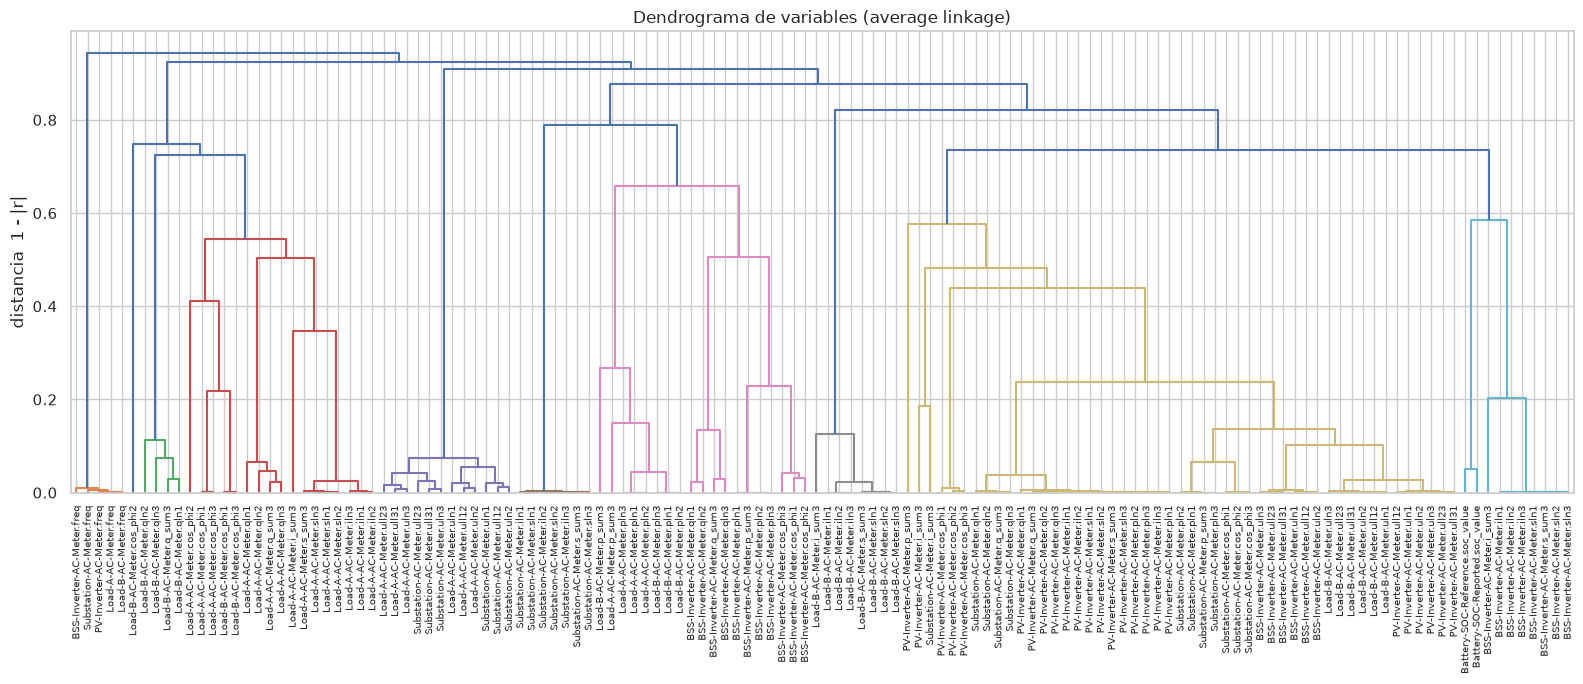

In [16]:

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

# --- correlación entre numéricas; |r| porque la relación puede ser inversa ---
X_num = dfX.select_dtypes(include=[np.number])
R = X_num.corr().abs().fillna(0)

# --- distancia 1-|r| y clustering jerárquico (average) ---
D = (1 - R).to_numpy().copy()
np.fill_diagonal(D, 0)
Z = linkage(squareform(D, checks=False), method="average")


# --- dendrograma con los nombres de columna en las hojas ---
fig, ax = plt.subplots(figsize=(16, 7))
dendrogram(Z, labels=X_num.columns.tolist(), leaf_rotation=90, leaf_font_size=7, ax=ax)
ax.set_ylabel("distancia  1 - |r|")
ax.set_title("Dendrograma de variables (average linkage)")
plt.tight_layout()
plt.show()

In [8]:
train.rf_logo(dfX.drop(columns="escenario"),dfY,dfX["escenario"])

,escenario,features,n,positivos,accuracy,precision,recall,f1,especificidad,auc,recall_5
fold,,,,,,,,,,,
1,S0,132,1798.00,0.00,0.442,0.000,0.000,0.000,0.442,NaN,NaN
2,S1,132,1798.00,913.00,0.492,0.000,0.000,0.000,1.000,0.737,0.249
3,S1-alt,132,1792.00,910.00,0.775,0.694,0.996,0.818,0.546,0.838,0.202
4,S2,132,1768.00,903.00,0.593,0.661,0.415,0.510,0.778,0.725,0.007
5,S3,132,1800.00,912.00,0.509,0.688,0.058,0.107,0.973,0.845,0.126
6,S4,132,1798.00,1257.00,0.667,0.977,0.537,0.693,0.970,0.902,0.606
7,S5,132,1800.00,1341.00,0.412,0.879,0.244,0.382,0.902,0.846,0.084
8,S6,132,1800.00,1350.00,0.471,0.969,0.304,0.462,0.971,0.938,0.523
mean,NaN,132,1794.25,948.25,0.545,0.608,0.319,0.372,0.823,0.833,0.257


In [7]:
train.rf_block_logo(dfX.drop(columns="escenario"), dfY, dfX["escenario"])

,escenario,features,n,positivos,accuracy,precision,recall,f1,especificidad,auc,recall_5
fold,,,,,,,,,,,
1,S0,29.000,1798.00,0.00,0.446,0.000,0.000,0.000,0.446,NaN,NaN
2,S1,28.000,1798.00,913.00,0.556,1.000,0.125,0.222,1.000,0.851,0.358
3,S1-alt,28.000,1792.00,910.00,0.758,0.681,0.988,0.806,0.522,0.866,0.389
4,S2,29.000,1768.00,903.00,0.558,0.619,0.351,0.448,0.775,0.742,0.002
5,S3,28.000,1800.00,912.00,0.501,0.724,0.023,0.045,0.991,0.820,0.240
6,S4,27.000,1798.00,1257.00,0.667,1.000,0.524,0.688,1.000,0.965,0.693
7,S5,27.000,1800.00,1341.00,0.597,0.936,0.493,0.646,0.902,0.940,0.433
8,S6,29.000,1800.00,1350.00,0.444,0.956,0.271,0.422,0.962,0.922,0.521
mean,NaN,28.125,1794.25,948.25,0.566,0.739,0.347,0.410,0.825,0.872,0.377


In [ ]:
X_win, y_win = split.aplanar_df(dfX, dfY,20)


In [13]:
train.rf_logo(X_win.drop(columns="escenario"),y_win,X_win["escenario"])

,escenario,features,n,positivos,accuracy,precision,recall,f1,especificidad,auc,recall_5
fold,,,,,,,,,,,
1,S0,2640,1779.00,0.00,0.446,0.000,0.000,0.000,0.446,NaN,NaN
2,S1,2640,1779.00,913.00,0.487,0.000,0.000,0.000,1.000,0.168,0.000
3,S1-alt,2640,1773.00,910.00,0.759,0.680,1.000,0.810,0.504,0.926,0.681
4,S2,2640,1749.00,903.00,0.579,0.645,0.409,0.500,0.760,0.736,0.000
5,S3,2640,1781.00,912.00,0.656,0.916,0.361,0.518,0.965,0.858,0.405
6,S4,2640,1779.00,1257.00,0.618,0.969,0.475,0.637,0.964,0.877,0.480
7,S5,2640,1781.00,1341.00,0.413,0.911,0.244,0.385,0.927,0.773,0.117
8,S6,2640,1781.00,1350.00,0.568,0.972,0.443,0.609,0.961,0.921,0.490
mean,NaN,2640,1775.25,948.25,0.566,0.637,0.367,0.432,0.816,0.751,0.310


In [85]:
train.rf_block_logo(X_win.drop(columns="escenario"), y_win, X_win["escenario"])       # tu df único con escenario + attack_active

/media/windows/Users/pablo/Documents/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab/Colab/src2/train.py:252: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  tabla.loc["mean"] = tabla.mean(numeric_only=True).round(3)
/media/windows/Users/pablo/Documents/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab/Colab/src2/train.py:252: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  tabla.loc["mean"] = tabla.mean(numeric_only=True).round(3)
/media/windows/Users/pablo/Documents/UNSA/4to/MetodosCuantit

,escenario,features,n,positivos,accuracy,precision,recall,f1,especificidad,auc,recall_5
fold,,,,,,,,,,,
1,S0,253.000,1779.00,0.00,0.362,0.000,0.000,0.000,0.362,NaN,NaN
2,S1,263.000,1779.00,913.00,0.574,1.000,0.170,0.290,1.000,0.890,0.497
3,S1-alt,255.000,1773.00,910.00,0.759,0.680,0.999,0.809,0.505,0.849,0.309
4,S2,264.000,1749.00,903.00,0.487,0.508,0.184,0.270,0.810,0.740,0.004
5,S3,265.000,1781.00,912.00,0.668,0.900,0.396,0.550,0.954,0.867,0.410
6,S4,268.000,1779.00,1257.00,0.654,1.000,0.511,0.676,1.000,0.962,0.704
7,S5,267.000,1781.00,1341.00,0.629,0.945,0.538,0.686,0.905,0.935,0.380
8,S6,248.000,1781.00,1350.00,0.317,0.993,0.099,0.180,0.998,0.943,0.556
mean,NaN,260.375,1775.25,948.25,0.556,0.753,0.362,0.433,0.817,0.884,0.409


## 6. La comparación que faltaba: block PCA sobre rango

El `02` viejo aplicaba `block_pca` sobre el **rango móvil** y lo elegía por AUC/recall@5. El EDA_grid lo aplica sobre **niveles crudos** y lo mira por accuracy a 0.5. No es la misma comparación.

Esta celda repite las cuatro combinaciones con la misma lógica de las celdas anteriores: `rf_logo` contra `rf_block_logo`, `GroupedPCA` ajustado por fold y las mismas métricas.

In [14]:
# === 6. La comparación que faltaba: block PCA sobre rango ===
from src2.features import rango_movil

# --- Rango móvil de 120 s, escenario por escenario ---
partes = []
for nombre in df["escenario"].unique():
    bloque = df.loc[df["escenario"] == nombre]
    partes.append(rango_movil(bloque.drop(columns=["escenario", "attack_active"]), 120))
X_rango = pd.concat(partes, ignore_index=True)

# --- Las cuatro configuraciones: niveles/rango × sin/block ---
tablas = {
    "niveles, sin reducción": train.rf_logo(dfX.drop(columns="escenario"), dfY, dfX["escenario"]),
    "niveles, block PCA": train.rf_block_logo(dfX.drop(columns="escenario"), dfY, dfX["escenario"]),
    "rango, sin reducción": train.rf_logo(X_rango, dfY, df["escenario"]),
    "rango, block PCA": train.rf_block_logo(X_rango, dfY, df["escenario"]),
}

# --- Resumen: ranking (AUC, recall@5) y punto de operación (accuracy, balanced acc) ---
filas = []
for nombre, tabla in tablas.items():
    d = tabla.drop(index="mean", errors="ignore")
    filas.append({
        "configuración": nombre,
        "features": int(d["features"].iloc[0]),
        "AUC media": d["auc"].mean(),
        "recall@5": d["recall_5"].mean(),
        "recall": d["recall"].mean(),
        "espec S0": float(d.loc[d.escenario == "S0", "especificidad"].iloc[0]),
        "accuracy": d["accuracy"].mean(),
        "balanced acc": ((d["recall"] + d["especificidad"]) / 2).mean(),
    })
resumen = pd.DataFrame(filas).set_index("configuración")
display(resumen.round(3))

,features,AUC media,recall@5,recall,espec S0,accuracy,balanced acc
configuración,,,,,,,
"niveles, sin reducción",132,0.833,0.257,0.319,0.442,0.545,0.571
"niveles, block PCA",29,0.872,0.375,0.347,0.446,0.566,0.586
"rango, sin reducción",132,0.877,0.455,0.600,0.515,0.729,0.714
"rango, block PCA",36,0.911,0.541,0.565,0.526,0.711,0.703


### Lectura

Qué debería mostrar esta tabla:

- **Sobre rango, block PCA sí mejora el ranking**: AUC 0.877 → 0.911 y recall@5 0.455 → 0.541.
- **Sobre niveles, la mejora es menor y parte de una base más baja**: AUC 0.833 → 0.872 y recall@5 0.257 → 0.377.
- **Accuracy@0.5 no acompaña**: en rango baja 0.729 → 0.711; en niveles sube 0.545 → 0.566. Es la métrica del corte 0.5, no la del ranking.
- **La especificidad en S0 queda pobre en las cuatro**: 0.44–0.53. Block PCA no arregla las falsas alarmas de un escenario limpio no visto.

Conclusión: el `02` viejo no se contradice. La diferencia era **representación** (rango vs niveles) y **métrica** (AUC/recall@5 vs accuracy a 0.5). Block PCA se elige por capacidad de detección a 5 % FPR, no por accuracy a 0.5.

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut
from sklearn.pipeline import Pipeline
from src2.features import rango_movil

from src2.group import GroupedPCA

import pandas as pd
from IPython.display import display

SEED = 42

PARAMS_RF = {
    "n_estimators": 120,
    "max_depth": 18,
    "min_samples_leaf": 2,
    "class_weight": "balanced",
    "random_state": SEED,
    "n_jobs": -1,
}
partes = []
for nombre in df["escenario"].unique():
    bloque = df.loc[df["escenario"] == nombre]
    partes.append(rango_movil(bloque.drop(columns=["escenario", "attack_active"]), 120))
X_rango = pd.concat(partes, ignore_index=True)
# --- Elegí la representación: "rango" o "niveles" ---
REPRESENTACION = "rango"
if REPRESENTACION == "rango":
    X_busqueda = X_rango
else:
    X_busqueda = dfX.drop(columns="escenario")

y_busqueda = dfY
grupos_busqueda = df["escenario"]

# --- Pipeline: imputar, block PCA, Random Forest fijo ---
pipeline = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("block", GroupedPCA(random_state=SEED)),
    ("rf", RandomForestClassifier(**PARAMS_RF)),
])

# --- Solo se tunea GroupedPCA ---
grilla = {
    "block__n_components": [0.90, 0.95, 0.99],
    "block__t": [0.2, 0.3, 0.4, 0.5],
}

busqueda = GridSearchCV(
    pipeline,
    grilla,
    cv=LeaveOneGroupOut(),
    scoring="accuracy",   # cambiá a "f1" o "balanced_accuracy" si preferís
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)
busqueda.fit(X_busqueda, y_busqueda, groups=grupos_busqueda)

print("mejor combinación:", busqueda.best_params_)
print("accuracy media LOSO:", round(busqueda.best_score_, 4))

resultados = pd.DataFrame(busqueda.cv_results_)
columnas = [
    "param_block__n_components",
    "param_block__t",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]
display(resultados[columnas].sort_values("rank_test_score").round(4))

Fitting 8 folds for each of 12 candidates, totalling 96 fits


/home/danilo/Windows_Compartido/Mis documentos/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/danilo/Windows_Compartido/Mis documentos/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/danilo/Windows_Compartido/Mis documentos/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should 

mejor combinación: {'block__n_components': 0.9, 'block__t': 0.5}
accuracy media LOSO: 0.7164


,param_block__n_components,param_block__t,mean_test_score,std_test_score,rank_test_score
3,0.90,0.5,0.7164,0.1549,1
8,0.99,0.2,0.7133,0.1547,2
5,0.95,0.3,0.7112,0.1502,3
6,0.95,0.4,0.7103,0.1503,4
4,0.95,0.2,0.7081,0.1439,5
2,0.90,0.4,0.7079,0.1398,6
7,0.95,0.5,0.7013,0.1615,7
0,0.90,0.2,0.7002,0.1488,8
10,0.99,0.4,0.6995,0.1594,9
1,0.90,0.3,0.6994,0.1309,10


In [14]:
from sklearn.base import clone
from src2.train import _metricas

filas = []
combinaciones = busqueda.cv_results_["params"]

for i, params in enumerate(combinaciones, start=1):
    print(f"combinación {i}/{len(combinaciones)}: {params}", flush=True)

    modelo_base = clone(busqueda.estimator).set_params(**params)
    por_fold = []

    for tr, te in LeaveOneGroupOut().split(X_busqueda, y_busqueda, groups=grupos_busqueda):
        modelo = clone(modelo_base).fit(X_busqueda.iloc[tr], y_busqueda.iloc[tr])
        proba = modelo.predict_proba(X_busqueda.iloc[te])[:, 1]
        fila = {"escenario": grupos_busqueda.iloc[te].iloc[0]}
        fila.update(_metricas(y_busqueda.iloc[te], proba))
        por_fold.append(fila)

    tabla_fold = pd.DataFrame(por_fold).set_index("escenario")
    filas.append({
        "n_components": params["block__n_components"],
        "t": params["block__t"],
        "AUC media": tabla_fold["auc"].mean(),
        "recall@5": tabla_fold["recall_5"].mean(),
        "recall": tabla_fold["recall"].mean(),
        "espec S0": float(tabla_fold.loc["S0", "especificidad"]),
        "accuracy": tabla_fold["accuracy"].mean(),
        "accuracy std": tabla_fold["accuracy"].std(),
    })

comparacion = pd.DataFrame(filas).sort_values("AUC media", ascending=False)
display(comparacion.round(3))

combinación 1/12: {'block__n_components': 0.9, 'block__t': 0.2}
combinación 2/12: {'block__n_components': 0.9, 'block__t': 0.3}
combinación 3/12: {'block__n_components': 0.9, 'block__t': 0.4}
combinación 4/12: {'block__n_components': 0.9, 'block__t': 0.5}
combinación 5/12: {'block__n_components': 0.95, 'block__t': 0.2}
combinación 6/12: {'block__n_components': 0.95, 'block__t': 0.3}
combinación 7/12: {'block__n_components': 0.95, 'block__t': 0.4}
combinación 8/12: {'block__n_components': 0.95, 'block__t': 0.5}
combinación 9/12: {'block__n_components': 0.99, 'block__t': 0.2}
combinación 10/12: {'block__n_components': 0.99, 'block__t': 0.3}
combinación 11/12: {'block__n_components': 0.99, 'block__t': 0.4}
combinación 12/12: {'block__n_components': 0.99, 'block__t': 0.5}


,n_components,t,AUC media,recall@5,recall,espec S0,accuracy,accuracy std
8,0.99,0.2,0.919,0.588,0.587,0.448,0.713,0.165
5,0.95,0.3,0.911,0.541,0.565,0.526,0.711,0.161
9,0.99,0.3,0.909,0.530,0.555,0.464,0.699,0.166
11,0.99,0.5,0.908,0.533,0.576,0.414,0.697,0.178
0,0.90,0.2,0.908,0.552,0.556,0.485,0.700,0.159
7,0.95,0.5,0.907,0.578,0.562,0.457,0.701,0.172
10,0.99,0.4,0.905,0.539,0.561,0.434,0.700,0.170
6,0.95,0.4,0.903,0.503,0.586,0.464,0.710,0.161
1,0.90,0.3,0.901,0.512,0.562,0.494,0.700,0.141
4,0.95,0.2,0.900,0.453,0.591,0.467,0.708,0.154


In [10]:
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
import src2.search as search

busqueda = search.buscar_grid_rfe(
    dfX,
    dfY,
    dfX["escenario"],
    RandomForestClassifier({
    "n_estimators": 120,
    "max_depth": 18,
    "min_samples_leaf": 2,
    "class_weight": "balanced",
    "random_state": 42,
    "n_jobs": -1,
}),
    n_features=[10, 20, 40, 80],
    step=5,
    espacio_modelo={"modelo__max_depth": [10, 18, None]},
)

Fitting 8 folds for each of 12 candidates, totalling 96 fits


ValueError: 
All the 96 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
12 fits failed with the following error:
Traceback (most recent call last):
  File "/home/danilo/Windows_Compartido/Mis documentos/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab/.venv/lib/python3.14/site-packages/sklearn/model_selection/_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/danilo/Windows_Compartido/Mis documentos/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab/.venv/lib/python3.14/site-packages/sklearn/base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "/home/danilo/Windows_Compartido/Mis documentos/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-col